# Scores, thresholds and rare classes

The churn model of Block 1 produces probabilities; the retention team needs a list of names, and the customers it most wants to find are the minority. After this block you can evaluate a classifier over all thresholds with the ROC curve, AUC and the precision–recall curve, choose a decision threshold from the costs of the two kinds of error, check whether predicted probabilities can be trusted (calibration), and handle class imbalance with class weights, undersampling, oversampling and SMOTE, applied only to the training data inside imbalanced-learn pipelines.

*Course material, licence CC BY 4.0. Sections marked "Adapted from" curate text and code from the scikit-learn example gallery (BSD-3-Clause), the INRIA scikit-learn MOOC (CC BY 4.0) and the imbalanced-learn examples (MIT); see [extras/README.md](extras/README.md). Data: IBM Telco customer churn sample (Apache 2.0), downloaded from IBM's GitHub repository.*

## Teaching map

The **core path** is what the lecturer teaches live in 45 minutes. Subsections marked *(depth: self-study or if time allows)* go further; the lecturer can skip them in class.

| Section | Core minutes | Core path | Depth subsections |
|---|---|---|---|
| Setup | 2 | the Telco pipeline of Block 1 | |
| 1 · The ROC curve and AUC | 7 | TPR, FPR, the curve, AUC as a ranking probability | AUC by counting pairs; scores, not classes; ROC for several classes |
| 2 · The precision–recall curve | 5 | precision against recall, average precision, chance level | AP and the trapezoid; curves per fold; iso-F1 lines; ROC and PR when positives are rare |
| 3 · Decision thresholds from the costs of errors | 9 | the rule *p > c / L*, the cost curve, `TunedThresholdClassifierCV` | gain matrices; tuning for another metric; how stable is the threshold; `cv="prefit"`; fixed thresholds; customer-specific costs; sensitivity to the cost assumptions |
| 4 · Calibration of predicted probabilities | 7 | calibration curve, Brier score, recalibration | histograms and log loss; sigmoid against isotonic; four churn models |
| 5 · Class imbalance and class weights | 6 | why accuracy misleads; `class_weight="balanced"` | weights from costs; weights distort probabilities; much rarer churn |
| 6 · Resampling inside the cross-validation with imbalanced-learn | 6 | samplers, the leak, the pipeline, the comparison | SMOTE step by step; SMOTENC; partial ratios and tuning; SMOTE variants; cleaning undersamplers |
| Worked example | 3 | which strategy is cheapest for the retention team | |
| **Theory total** | **45** | then exercises (30) and debrief (15) | |

```mermaid
flowchart LR
    M["Fitted classifier"] --> P["Probabilities<br/>predict_proba"]
    P --> R["Ranking quality:<br/>ROC AUC, PR curve"]
    P --> CAL{"Calibrated?"}
    CAL -->|no| FIX["Recalibrate:<br/>CalibratedClassifierCV"]
    CAL -->|yes| TH["Threshold from<br/>error costs"]
    FIX --> TH
    TH --> D["Decision:<br/>offer / no offer"]
    IMB["Rare class:<br/>weights or resampling<br/>(training folds only)"] --> M
```

## Setup · the churn pipeline of Block 1

We rebuild the Telco data, the split and the two pipelines of Block 1: logistic regression and 50-nearest neighbours. Nothing here is new; the cell is long only because it repeats Block 1.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
telco = pd.read_csv(URL)
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce")
y = (telco["Churn"] == "Yes").astype(int)
X = telco.drop(columns=["customerID", "Churn"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
numeric = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
categorical = [c for c in X.columns if c not in numeric]
pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
])
logreg = make_pipeline(pre, LogisticRegression(max_iter=1000)).fit(X_train, y_train)
knn = make_pipeline(pre, KNeighborsClassifier(n_neighbors=50)).fit(X_train, y_train)
proba_lr = logreg.predict_proba(X_test)[:, 1]
proba_knn = knn.predict_proba(X_test)[:, 1]
print(len(X_train), "training and", len(X_test), "test customers; churn rate", round(y.mean(), 3))

5282 training and 1761 test customers; churn rate 0.265


## 1 · The ROC curve and AUC

A classifier outputs a score or probability; a **threshold** turns it into a class (by default 0.5). Every threshold gives one confusion matrix and therefore one pair of rates:

- the **true positive rate** (TPR, recall, sensitivity) = TP / (TP + FN): the share of churners we flag;
- the **false positive rate** (FPR) = FP / (FP + TN): the share of loyal customers we flag by mistake (1 − specificity).

The **ROC curve** (receiver operating characteristic, a name from radar engineering) plots TPR against FPR for all thresholds, from "flag nobody" at (0, 0) to "flag everybody" at (1, 1). The top-left corner is the ideal: all churners, no false alarms. A random ranking lies on the diagonal.

The **area under the curve** (ROC AUC) summarises the curve in one number. It has a plain meaning: **the probability that a randomly chosen churner gets a higher score than a randomly chosen loyal customer**. 0.5 is coin-tossing; 1.0 is a perfect ranking. AUC does not depend on any threshold, so it compares models before the business has chosen one.

Small example: four customers with scores 0.9 (churns), 0.6 (stays), 0.4 (churns), 0.2 (stays). Of the 2 × 2 = 4 churner–stayer pairs, the churner has the higher score in 3. AUC = 3/4 = 0.75.

**Predict before running.** Which of the two models will have the higher AUC, and will the toy example give 0.75?

`roc_auc_score(y_true, scores)` needs **scores**, here the probabilities from `predict_proba(X)[:, 1]`, not predicted classes. `roc_curve` returns the FPR, the TPR and the thresholds at which they change.

In [2]:
from sklearn.metrics import roc_auc_score, roc_curve

print("AUC logistic regression", round(roc_auc_score(y_test, proba_lr), 3),
      "| AUC 50-NN", round(roc_auc_score(y_test, proba_knn), 3))
print("toy example:", roc_auc_score([1, 0, 1, 0], [0.9, 0.6, 0.4, 0.2]))

fpr, tpr, thresholds = roc_curve(y_test, proba_lr)
i = np.argmin(np.abs(thresholds - 0.5))
print("at threshold 0.5: FPR", round(fpr[i], 3), " TPR", round(tpr[i], 3))

AUC logistic regression 0.844 | AUC 50-NN 0.834
toy example: 0.75
at threshold 0.5: FPR 0.114  TPR 0.531


`RocCurveDisplay.from_predictions(y, scores, name=...)` draws a curve; `plot_chance_level=True` adds the diagonal. We mark the point of the default threshold 0.5.

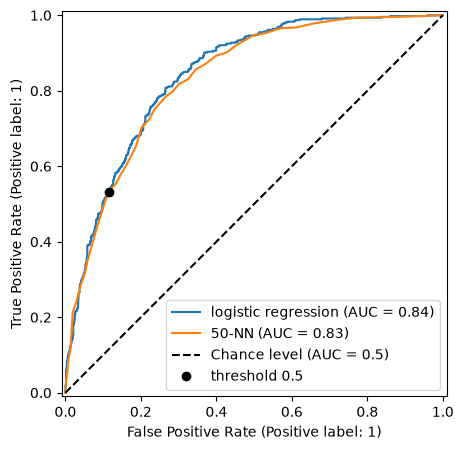

In [3]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_predictions(y_test, proba_lr, name="logistic regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, proba_knn, name="50-NN", ax=ax, plot_chance_level=True)
ax.plot(fpr[i], tpr[i], "ko", label="threshold 0.5")
ax.legend(loc="lower right")
plt.show()

The two curves almost coincide: the models rank customers about equally well. At the default threshold the logistic regression flags about one loyal customer in nine and finds about half of the churners; moving along the curve trades one for the other.

> **Note.** In credit scoring the same number is reported as the **Gini coefficient**, 2 · AUC − 1, which runs from 0 (random) to 1 (perfect).

### AUC by counting pairs (depth: self-study or if time allows)

The claim "AUC is the share of correctly ranked churner–stayer pairs" can be checked directly. With 467 churners and 1,294 loyal customers in the test set there are about 600,000 pairs. NumPy broadcasting compares all of them at once: `s_churn[:, None] > s_stay[None, :]` is a churners × stayers table of True/False. Ties count one half.

In [4]:
s_churn, s_stay = proba_lr[y_test.to_numpy() == 1], proba_lr[y_test.to_numpy() == 0]
wins = (s_churn[:, None] > s_stay[None, :]).mean() + 0.5 * (s_churn[:, None] == s_stay[None, :]).mean()
print(len(s_churn) * len(s_stay), "pairs | share ranked correctly", round(wins, 4),
      "| roc_auc_score", round(roc_auc_score(y_test, proba_lr), 4))

604298 pairs | share ranked correctly 0.8438 | roc_auc_score 0.8438


### Scores, not classes (depth: self-study or if time allows)

Passing predicted classes (0/1) instead of probabilities gives a "curve" with a single corner at the 0.5 threshold, and an AUC that only reflects that one point. Every churner–stayer pair with the same predicted class becomes a tie.

In [5]:
print("AUC from probabilities", round(roc_auc_score(y_test, proba_lr), 3),
      "| AUC from 0/1 predictions", round(roc_auc_score(y_test, logreg.predict(X_test)), 3))

AUC from probabilities 0.844 | AUC from 0/1 predictions 0.708


### ROC curves for several classes (depth: self-study or if time allows)

*Adapted from [Multiclass Receiver Operating Characteristic (ROC)](https://scikit-learn.org/1.9/auto_examples/model_selection/plot_roc.html) (scikit-learn developers, BSD-3-Clause).*

TPR and FPR are defined for two classes. With more classes the output must first be binarised, in one of two ways:

- **One-vs-Rest (OvR)**: each class in turn is "positive" and all the others together are "negative"; one ROC curve per class.
- **One-vs-One (OvO)**: every pair of classes is compared, using only the cases of those two classes; *K*(*K* − 1)/2 comparisons for *K* classes.

The per-class results are then averaged. **Macro-averaging** computes the AUC per class and takes the plain mean: every class counts equally. **Micro-averaging** pools all binarised decisions into one big binary problem: every case counts equally, so big classes dominate. Micro-averaging is defined only for OvR.

> **Note.** OvR *evaluation* is not the same as OvR *training* (fitting one binary model per class with `OneVsRestClassifier`). Any multiclass model can be evaluated with OvR or OvO curves, however it was trained.

We use the three-class task of Block 1: predict a customer's **contract** from everything else. `predict_proba` now returns one column per class.

In [6]:
Xc = X.drop(columns="Contract")
yc = X["Contract"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=0)
pre_c = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), [c for c in categorical if c != "Contract"]),
])
contract_model = make_pipeline(pre_c, LogisticRegression(max_iter=2000)).fit(Xc_train, yc_train)
yc_score = contract_model.predict_proba(Xc_test)
print(contract_model.classes_, yc_score[:2].round(2))

['Month-to-month' 'One year' 'Two year'] [[0.98 0.02 0.  ]
 [0.62 0.24 0.14]]


`roc_auc_score(y, scores, multi_class="ovr" or "ovo", average="macro" or "micro")` computes the averaged AUCs directly.

In [7]:
for mc, avg in [("ovr", "macro"), ("ovr", "micro"), ("ovo", "macro")]:
    print(f"{mc} {avg:5s} AUC", round(roc_auc_score(yc_test, yc_score, multi_class=mc, average=avg), 3))

ovr macro AUC 0.892
ovr micro AUC 0.917
ovo macro AUC 0.869


To draw one OvR curve per class, `LabelBinarizer` turns the labels into a 0/1 column per class (a one-hot encoding of the target). Each column, with the matching probability column, is a binary problem. The micro-average curve uses all columns flattened with `.ravel()`.

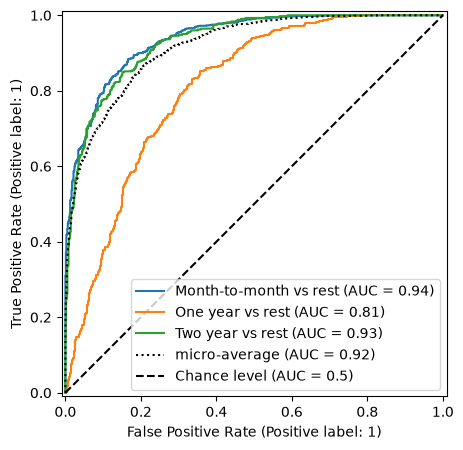

In [8]:
from sklearn.preprocessing import LabelBinarizer

Y_onehot = LabelBinarizer().fit(yc_train).transform(yc_test)
fig, ax = plt.subplots(figsize=(5.5, 5))
for k, name in enumerate(contract_model.classes_):
    RocCurveDisplay.from_predictions(Y_onehot[:, k], yc_score[:, k], name=f"{name} vs rest", ax=ax)
RocCurveDisplay.from_predictions(Y_onehot.ravel(), yc_score.ravel(), name="micro-average", ax=ax,
                                 curve_kwargs={"linestyle": ":", "color": "black"}, plot_chance_level=True)
plt.show()

"One year" against the rest is the weakest curve, as its F1 was in Block 1: it is the middle class, confused with both neighbours. Which average to report depends on the question. Macro-averaging treats rare classes as important as frequent ones, which is what Session 13's customs task needs; micro-averaging describes the experience of a typical case and is dominated by the big classes.

> 📖 **Read more:** [extras/07-roc-curve.ipynb](extras/07-roc-curve.ipynb) (scikit-learn gallery): OvR and OvO curves on the iris data, with the averages computed by hand.

## 2 · The precision–recall curve

The **precision–recall (PR) curve** plots precision against recall for all thresholds. A high threshold flags few customers, mostly correctly (high precision, low recall); lowering it moves to the right (more recall, usually lower precision). It ignores the true negatives entirely and looks only at the positive class.

A random ranking has a precision equal to the share of positives at every recall, here about 0.265: the **chance level** of the PR curve depends on the data, unlike the diagonal of the ROC curve. **Average precision** (AP) summarises the curve: the mean of the precisions at all thresholds, each weighted by how much recall increased at that threshold.

When positives are rare and the business works through a ranked list (call the 500 riskiest customers, review the top 100 transactions), precision at a given recall is the number that matters.

`average_precision_score(y, scores)` computes AP; `precision_recall_curve` returns precision, recall and thresholds. Next we find the highest threshold that still catches 80 % of the churners.

In [9]:
from sklearn.metrics import average_precision_score, precision_recall_curve

print("AP logistic regression", round(average_precision_score(y_test, proba_lr), 3),
      "| AP 50-NN", round(average_precision_score(y_test, proba_knn), 3),
      "| chance level", round(y_test.mean(), 3))
precision, recall, thr = precision_recall_curve(y_test, proba_lr)
ok = recall[:-1] >= 0.8
best = np.argmax(np.where(ok, precision[:-1], 0))
print("to find 80 % of churners: threshold", round(thr[best], 3), "precision", round(precision[best], 3))

AP logistic regression 0.638 | AP 50-NN 0.617 | chance level 0.265
to find 80 % of churners: threshold 0.268 precision 0.524


To reach 80 % of the churners, about every second customer we call would have stayed anyway. `PrecisionRecallDisplay.from_predictions` draws the curves; `plot_chance_level=True` adds the horizontal chance line.

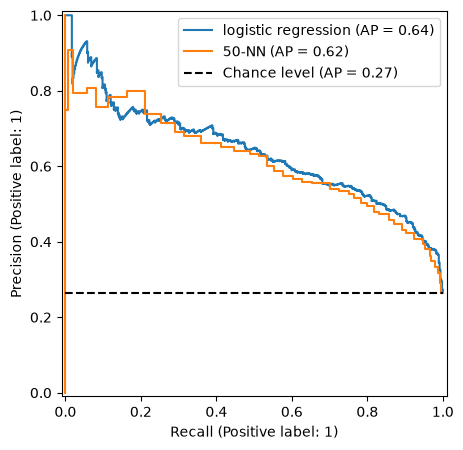

In [10]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(5.5, 5))
PrecisionRecallDisplay.from_predictions(y_test, proba_lr, name="logistic regression", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, proba_knn, name="50-NN", ax=ax, plot_chance_level=True)
ax.legend(loc="upper right")
plt.show()

> **Note.** Which summary fits? If the question is "rank customers by risk", report ROC AUC and AP. If it is "who gets an offer this month", report precision and recall at the chosen threshold, ideally with the cost of the errors (Section 3).

### How the curve moves, AP and the trapezoid (depth: self-study or if time allows)

*Adapted from [Precision-Recall](https://scikit-learn.org/1.9/auto_examples/model_selection/plot_precision_recall.html) (scikit-learn developers, BSD-3-Clause).*

Recall = TP / (TP + FN) has a denominator that does not depend on the threshold (the number of churners), so lowering the threshold can only raise recall or leave it unchanged. Precision = TP / (TP + FP) has a denominator that grows as more customers are flagged. If the newly flagged customers happen to be churners, precision rises; if they are loyal, it falls. So precision does not necessarily decrease with recall, which gives the PR curve its saw-tooth shape.

Average precision is AP = Σ (R_n − R_(n−1)) · P_n over the thresholds. The trapezoidal area under the points (`sklearn.metrics.auc(recall, precision)`) interpolates linearly between the points and is slightly optimistic; the two numbers differ. Report which one you use.

In [11]:
from sklearn.metrics import auc

print("average precision", round(average_precision_score(y_test, proba_lr), 4),
      "| trapezoidal area", round(auc(recall, precision), 4))

average precision 0.6377 | trapezoidal area 0.637


### One curve per cross-validation fold (depth: self-study or if time allows)

*Adapted from [Precision-Recall](https://scikit-learn.org/1.9/auto_examples/model_selection/plot_precision_recall.html) (scikit-learn developers, BSD-3-Clause).*

A single test set gives one curve. `cross_validate(..., return_estimator=True, return_indices=True)` keeps the five fitted models and their validation rows, and `PrecisionRecallDisplay.from_cv_results` draws one curve per fold. The spread shows how much the curve depends on which customers happened to be in the validation fold.

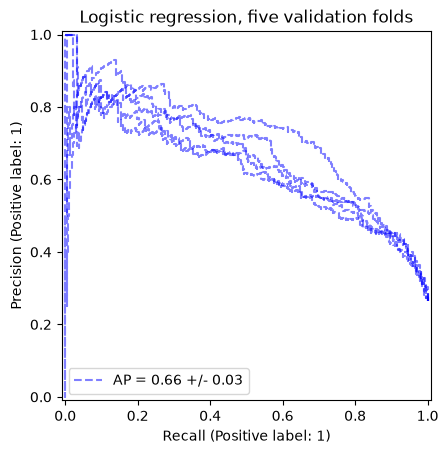

In [12]:
from sklearn.model_selection import cross_validate

cv_results = cross_validate(logreg, X_train, y_train, cv=cv, return_estimator=True, return_indices=True)
display = PrecisionRecallDisplay.from_cv_results(cv_results, X_train, y_train)
display.ax_.set_title("Logistic regression, five validation folds")
plt.show()

### Iso-F1 lines (depth: self-study or if time allows)

*Adapted from [Precision-Recall](https://scikit-learn.org/1.9/auto_examples/model_selection/plot_precision_recall.html) (scikit-learn developers, BSD-3-Clause).*

All points with the same F1 lie on a curve: from F1 = 2PR / (P + R) it follows that P = F1 · R / (2R − F1). Drawing these **iso-F1 lines** behind a PR curve shows where along the curve F1 is highest, and that F1 rewards a balance of precision and recall.

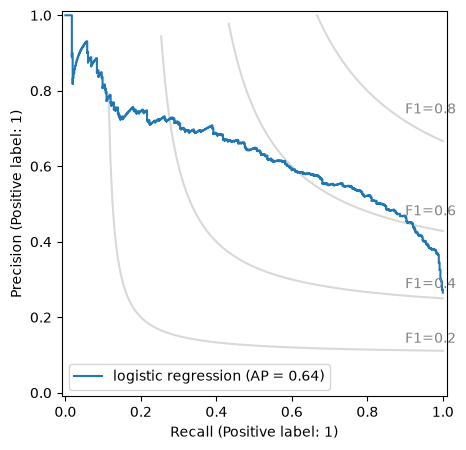

In [13]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for f in [0.2, 0.4, 0.6, 0.8]:
    r = np.linspace(0.01, 1, 200)
    p = f * r / (2 * r - f)
    keep = (p >= 0) & (p <= 1)
    ax.plot(r[keep], p[keep], color="grey", alpha=0.3)
    ax.annotate(f"F1={f}", xy=(0.9, f * 0.9 / (1.8 - f) + 0.02), color="grey")
PrecisionRecallDisplay.from_predictions(y_test, proba_lr, name="logistic regression", ax=ax)
plt.show()

### ROC and PR when positives are rare (depth: self-study or if time allows)

The FPR is computed over all negatives. When negatives vastly outnumber positives (fraud at 0.1 %), even many false alarms are a small share of them, so the ROC curve can look excellent while precision is poor (Saito & Rehmsmeier, 2015). We simulate this: keep all loyal test customers but only 40 churners, so that churners are about 3 % of the cases, and compare the summaries.

In [14]:
rng = np.random.default_rng(0)
churn_idx = np.flatnonzero(y_test.to_numpy() == 1)
keep = np.r_[np.flatnonzero(y_test.to_numpy() == 0), rng.choice(churn_idx, 40, replace=False)]
y_rare, p_rare = y_test.to_numpy()[keep], proba_lr[keep]
for name, yy, pp in [("all test customers", y_test, proba_lr), ("churners made rare", y_rare, p_rare)]:
    print(f"{name:19s} churn share {np.mean(yy):.3f}  ROC AUC {roc_auc_score(yy, pp):.3f}  AP {average_precision_score(yy, pp):.3f}")

all test customers  churn share 0.265  ROC AUC 0.844  AP 0.638
churners made rare  churn share 0.030  ROC AUC 0.799  AP 0.142


Average precision collapses, from about 0.64 to about 0.14, because the same false alarms now outnumber far fewer true churners. The ROC AUC changes much less; it moves at all only because the 40 churners drawn are a small random sample, whose expected AUC is the same as before. For rare positives, look at the PR curve.

> 📖 **Read more:** [extras/08-precision-recall-curve.ipynb](extras/08-precision-recall-curve.ipynb) (scikit-learn gallery): PR curves, average precision, per-fold curves and the multi-label case. [extras/06-classification-metrics.ipynb](extras/06-classification-metrics.ipynb) (INRIA) shows both curves next to a dummy baseline.

## 3 · Decision thresholds from the costs of errors

`predict` flags a customer if the predicted churn probability is at least 0.5. That choice silently assumes that a false positive and a false negative cost the same, which is rarely true. Suppose

- every flagged customer receives a retention offer that costs **c = €100**, and the offer keeps a churner;
- every churner who is not flagged is lost, which costs **L = €400** in future margin.

For a customer with churn probability *p*, flagging costs €100 for sure; not flagging costs €400 with probability *p*, so €400 · *p* on average. Flagging is cheaper when 400 · *p* > 100, that is when **p > c / L = 0.25**. The cost-optimal threshold is 0.25, not 0.5 (Elkan, 2001).

This rule holds only if the probabilities are **calibrated** (Section 4). In practice we also check it empirically: compute the total cost for a grid of thresholds on **validation** data, never on the test set, and take the minimum. Choosing the threshold on the test set would be tuning on the test set (Session 7).

`cross_val_predict(model, X, y, cv=cv, method="predict_proba")` gives an honest, out-of-fold probability for every training customer. The function `cost` adds €100 per flagged customer and €400 per missed churner.

In [15]:
from sklearn.model_selection import cross_val_predict

OFFER, LOST = 100, 400


def cost(y_true, proba, t, offer=OFFER, lost=LOST):
    flagged = proba >= t
    return offer * flagged.sum() + lost * (~flagged & (np.asarray(y_true) == 1)).sum()


oof = cross_val_predict(logreg, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
ts = np.round(np.arange(0.02, 0.99, 0.01), 2)
costs = np.array([cost(y_train, oof, t) for t in ts])
t_best = ts[costs.argmin()]
print("best threshold", t_best, "| rule c / L", OFFER / LOST)
print("cost per customer: best", round(costs.min() / len(y_train), 1), "| at 0.5", round(cost(y_train, oof, 0.5) / len(y_train), 1))

best threshold 0.27 | rule c / L 0.25
cost per customer: best 62.1 | at 0.5 69.6


The cost curve shows how much the choice matters. A flat curve near the optimum means the exact threshold matters little; a steep one means the cost assumptions deserve a second look with the business owner.

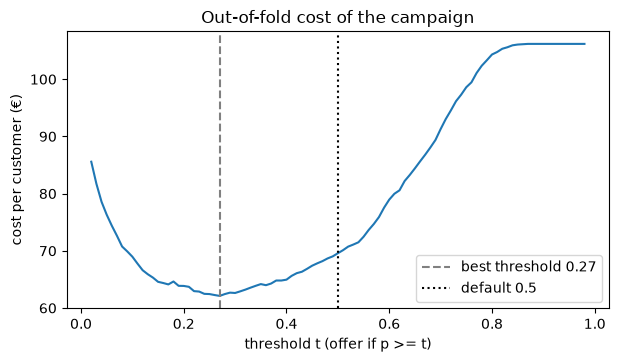

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(ts, costs / len(y_train))
ax.axvline(t_best, ls="--", color="grey", label=f"best threshold {t_best}")
ax.axvline(0.5, ls=":", color="black", label="default 0.5")
ax.set(xlabel="threshold t (offer if p >= t)", ylabel="cost per customer (€)", title="Out-of-fold cost of the campaign")
ax.legend()
plt.show()

**Predict before running.** We now look at the test set once. Will the chosen threshold beat 0.5 there too, and by how much compared with "no offers" and "offers to everybody"?

In [17]:
strategies = {"no offers": np.inf, "offers to everybody": 0.0, "default 0.5": 0.5, "chosen on training folds": t_best}
pd.DataFrame([{"strategy": k, "threshold": t, "offers": int((proba_lr >= t).sum()),
               "cost on test (€)": cost(y_test, proba_lr, t)} for k, t in strategies.items()])

,strategy,threshold,offers,cost on test (€)
0,no offers,inf,0,186800
1,offers to everybody,0.00,1761,176100
2,default 0.5,0.50,396,127200
3,chosen on training folds,0.27,714,109400


scikit-learn automates the search with **`TunedThresholdClassifierCV`**: it cross-validates the threshold for any scoring function and then refits the model on all training data. The scorer must follow the convention "higher is better", so it returns minus the cost. `make_scorer(function)` turns a function of `(y_true, y_pred)` into a scorer.

In [18]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import TunedThresholdClassifierCV


def gain(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return -(OFFER * (y_pred == 1).sum() + LOST * ((y_true == 1) & (y_pred == 0)).sum())


tuned = TunedThresholdClassifierCV(logreg, scoring=make_scorer(gain), cv=5, random_state=0,
                                   store_cv_results=True).fit(X_train, y_train)
print("cross-validated threshold", round(tuned.best_threshold_, 3),
      "| cost on test", -gain(y_test, tuned.predict(X_test)))

cross-validated threshold 0.295 | cost on test 109500


The tuned threshold lands close to the manual choice and to the formula *c / L*, which is a first sign that the logistic regression's probabilities are well calibrated.

> 📖 **Read more:** [extras/09-tuned-decision-threshold.ipynb](extras/09-tuned-decision-threshold.ipynb) and [extras/10-cost-sensitive-learning.ipynb](extras/10-cost-sensitive-learning.ipynb) (scikit-learn gallery): the sources of the depth subsections below, on the diabetes, German credit and credit-card fraud data.

### Costs as a gain matrix (depth: self-study or if time allows)

*Adapted from [Post-tuning the decision threshold for cost-sensitive learning](https://scikit-learn.org/1.9/auto_examples/model_selection/plot_cost_sensitive_learning.html) (scikit-learn developers, BSD-3-Clause).*

A compact way to write a business metric is a **gain matrix** of the same shape as the confusion matrix (truth in rows, prediction in columns): each cell says what one case of that kind is worth. Multiplying the confusion matrix by the gain matrix cell by cell and adding everything up gives the total gain. For the retention campaign, a flagged customer costs €100 whether or not they churn, and a missed churner costs €400:

| | predicted: stays | predicted: churns |
|---|---|---|
| **truly stays** | 0 | −100 |
| **truly churns** | −400 | −100 |

Any business metric of this kind can be plugged into `TunedThresholdClassifierCV`. With `store_cv_results=True` the tuned model keeps the objective for every threshold it tried, so we can plot it.

same as gain(): True


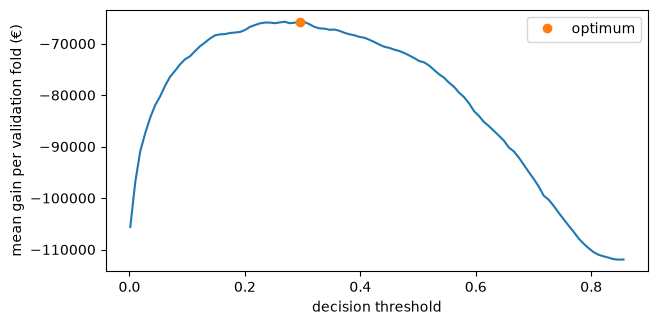

In [19]:
from sklearn.metrics import confusion_matrix

GAIN = np.array([[0, -OFFER], [-LOST, -OFFER]])


def gain_matrix_score(y_true, y_pred):
    return np.sum(confusion_matrix(y_true, y_pred, labels=[0, 1]) * GAIN)


print("same as gain():", gain_matrix_score(y_test, tuned.predict(X_test)) == gain(y_test, tuned.predict(X_test)))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(tuned.cv_results_["thresholds"], tuned.cv_results_["scores"])
ax.plot(tuned.best_threshold_, tuned.best_score_, "o", label="optimum")
ax.set(xlabel="decision threshold", ylabel="mean gain per validation fold (€)")
ax.legend()
plt.show()

### Tuning for another metric (depth: self-study or if time allows)

*Adapted from [Post-hoc tuning the cut-off point of decision function](https://scikit-learn.org/1.9/auto_examples/model_selection/plot_tuned_decision_threshold.html) (scikit-learn developers, BSD-3-Clause).*

When no costs are known, the threshold can be tuned for a metric such as **balanced accuracy** (the mean recall of the two classes, Block 1). The tuned model is internally the *same* model: it has exactly the same coefficients; only the cut-off differs. That is why its ROC curve is identical.

In [20]:
from sklearn.metrics import balanced_accuracy_score

tuned_ba = TunedThresholdClassifierCV(logreg, scoring="balanced_accuracy", cv=5, random_state=0).fit(X_train, y_train)
print("threshold for balanced accuracy", round(tuned_ba.best_threshold_, 3))
for name, m in [("default 0.5", logreg), ("tuned", tuned_ba)]:
    p = m.predict(X_test)
    print(f"{name:12s} accuracy {np.mean(p == y_test):.3f}  balanced accuracy {balanced_accuracy_score(y_test, p):.3f}")
print("same coefficients:", np.allclose(tuned_ba.estimator_[-1].coef_, logreg[-1].coef_))

threshold for balanced accuracy 0.295
default 0.5  accuracy 0.792  balanced accuracy 0.708
tuned        accuracy 0.763  balanced accuracy 0.767
same coefficients: True


Balanced accuracy goes up, plain accuracy goes down: the tuned model is more eager to say "churns" and makes more mistakes on the loyal customers. Which metric to tune for is a business decision, not a statistical one.

### How stable is the tuned threshold? (depth: self-study or if time allows)

*Adapted from [Post-hoc tuning the cut-off point of decision function](https://scikit-learn.org/1.9/auto_examples/model_selection/plot_tuned_decision_threshold.html) (scikit-learn developers, BSD-3-Clause).*

The tuned threshold is itself an estimate from data. Wrapping the tuned model in `cross_validate(..., return_estimator=True)` refits it on ten different training sets (`RepeatedStratifiedKFold` with 5 folds, repeated twice) and shows how much the chosen threshold varies.

In [21]:
from sklearn.model_selection import RepeatedStratifiedKFold

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=0)
res = cross_validate(TunedThresholdClassifierCV(logreg, scoring=make_scorer(gain), cv=5, random_state=0),
                     X_train, y_train, cv=rcv, return_estimator=True)
chosen = pd.Series([est.best_threshold_ for est in res["estimator"]])
print(chosen.round(3).describe()[["mean", "std", "min", "max"]].round(3).to_dict())

{'mean': 0.268, 'std': 0.023, 'min': 0.234, 'max': 0.298}


Across ten training sets the chosen threshold varies by several hundredths around the value *c / L* = 0.25. That variation matters little here, because the cost curve of Section 3 is flat near its minimum.

### Tuning on the training data itself: `cv="prefit"` (depth: self-study or if time allows)

*Adapted from [Post-tuning the decision threshold for cost-sensitive learning](https://scikit-learn.org/1.9/auto_examples/model_selection/plot_cost_sensitive_learning.html) (scikit-learn developers, BSD-3-Clause).*

`TunedThresholdClassifierCV` can skip the cross-validation: with an already fitted model, `cv="prefit"` and `refit=False` it searches the threshold on whatever data you pass to `fit`. If that is the training data, the threshold is chosen on predictions the model has already seen, the same mistake as tuning on the test set. For a flexible model the result can be badly off. The option is meant for a **separate validation set**; `cv=0.25` instead holds out a quarter of the training data once.

In [22]:
from sklearn.ensemble import RandomForestClassifier

forest = make_pipeline(pre, RandomForestClassifier(n_estimators=200, min_samples_leaf=2, random_state=0, n_jobs=-1))
forest.fit(X_train, y_train)
for name, kw in [("prefit on training data", {"cv": "prefit", "refit": False}), ("cross-validated", {"cv": 5})]:
    t = TunedThresholdClassifierCV(forest, scoring=make_scorer(gain), random_state=0, **kw).fit(X_train, y_train)
    print(f"{name:24s} threshold {t.best_threshold_:.3f}   cost on test {-gain(y_test, t.predict(X_test))}")

prefit on training data  threshold 0.376   cost on test 118200


cross-validated          threshold 0.229   cost on test 113500


The forest's probabilities on its own training customers are over-confident, so the threshold chosen there is too high, and the test cost is higher than with the cross-validated threshold.

### Fixing a threshold by hand (depth: self-study or if time allows)

*Adapted from [Post-tuning the decision threshold for cost-sensitive learning](https://scikit-learn.org/1.9/auto_examples/model_selection/plot_cost_sensitive_learning.html) (scikit-learn developers, BSD-3-Clause).*

When the threshold is known in advance (from the formula, or agreed with the business), `FixedThresholdClassifier(estimator, threshold=t)` applies it without any search. `FrozenEstimator` wraps an already fitted model so that it is not refitted. The result is a normal estimator whose `predict` uses the new threshold, which is convenient for deployment (Session 16).

In [23]:
from sklearn.frozen import FrozenEstimator
from sklearn.model_selection import FixedThresholdClassifier

fixed = FixedThresholdClassifier(FrozenEstimator(logreg), threshold=OFFER / LOST).fit(X_train, y_train)
print("offers at t = c / L:", fixed.predict(X_test).sum(), "| cost on test", -gain(y_test, fixed.predict(X_test)))

offers at t = c / L: 752 | cost on test 109200


### When every customer has a different value (depth: self-study or if time allows)

*Adapted from [Post-tuning the decision threshold for cost-sensitive learning](https://scikit-learn.org/1.9/auto_examples/model_selection/plot_cost_sensitive_learning.html) (scikit-learn developers, BSD-3-Clause), where the cost of a missed fraud is the amount of the transaction.*

A lost customer who pays $110 a month costs more than one who pays $20. Suppose the value of a lost customer is one year of their charges, L_i = 12 × MonthlyCharges_i (in the data's currency, treated here as euros), and an offer still costs €100. Then the rule becomes customer-specific: **offer if p_i · L_i > c**. A single threshold on *p* can no longer be optimal, but we can still tune one, using **metadata routing**: the scorer asks for the extra column `value` with `set_score_request(value=True)`, and `TunedThresholdClassifierCV.fit(..., value=...)` passes it on.

In [24]:
import sklearn

sklearn.set_config(enable_metadata_routing=True)


def value_gain(y_true, y_pred, value):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return -(OFFER * (y_pred == 1).sum() + value[(y_true == 1) & (y_pred == 0)].sum())


value_scorer = make_scorer(value_gain).set_score_request(value=True)
value_train, value_test = 12 * X_train["MonthlyCharges"].to_numpy(), 12 * X_test["MonthlyCharges"].to_numpy()
tuned_v = TunedThresholdClassifierCV(logreg, scoring=value_scorer, cv=5, random_state=0).fit(X_train, y_train, value=value_train)
sklearn.set_config(enable_metadata_routing=False)
print("mean value of a customer", round(value_train.mean()), "| tuned single threshold", round(tuned_v.best_threshold_, 3))

mean value of a customer 772 | tuned single threshold 0.122


Now we compare three policies on the test customers: the default 0.5, the tuned single threshold, and the customer-specific rule *p_i · L_i > c*, which needs no tuning at all if the probabilities are calibrated.

In [25]:
policies = {"default 0.5": proba_lr >= 0.5,
            "tuned single threshold": proba_lr >= tuned_v.best_threshold_,
            "customer-specific p * L > c": proba_lr * value_test > OFFER}
for name, flag in policies.items():
    print(f"{name:28s} offers {flag.sum():4d}   cost on test €{-value_gain(y_test, flag.astype(int), value_test):,.0f}")

default 0.5                  offers  396   cost on test €226,307
tuned single threshold       offers 1021   cost on test €131,465
customer-specific p * L > c  offers  977   cost on test €127,787


The customer-specific rule spends offers where the expected loss is largest. Its advantage over a single threshold depends on how much customer values differ; here charges range from about €18 to €119 a month. As the gallery example stresses, a cost estimated on historical data is itself uncertain; before a large campaign the policy should be confirmed in a controlled experiment (an A/B test).

### How much do the cost assumptions matter? (depth: self-study or if time allows)

Nobody knows the value of a lost customer exactly, and an offer does not save every churner. If an offer keeps a churner with probability *s*, flagging a customer with churn probability *p* saves *s · L · p* on average and costs *c*, so the rule becomes **p > c / (s · L)**. We repeat the out-of-fold search for a range of values. A flagged churner who is not saved still costs *L*, so the expected cost of a flagged churner is (1 − *s*) · *L* on top of the offer.

In [26]:
rows = []
for lost in [200, 400, 800]:
    for success in [1.0, 0.5]:
        c = [OFFER * (oof >= t).sum() + lost * ((oof < t) & (y_train == 1)).sum()
             + (1 - success) * lost * ((oof >= t) & (y_train == 1)).sum() for t in ts]
        t_opt = ts[int(np.argmin(c))]
        rows.append({"lost customer €": lost, "offer success": success, "best threshold": t_opt,
                     "rule c / (s L)": round(OFFER / (success * lost), 3), "share flagged": round((oof >= t_opt).mean(), 3)})
pd.DataFrame(rows)

,lost customer €,offer success,best threshold,rule c / (s L),share flagged
0,200,1.0,0.54,0.500,0.197
1,200,0.5,0.85,1.000,0.000
2,400,1.0,0.27,0.250,0.402
3,400,0.5,0.54,0.500,0.197
4,800,1.0,0.15,0.125,0.553
5,800,0.5,0.27,0.250,0.402


The empirical optimum follows the rule *c / (s · L)* closely in every scenario. When the rule gives a threshold of 1 or more (an offer that saves only every second customer worth €200 can never pay for itself), the best policy is to send no offers at all. A short table like this is what the retention team needs to discuss the assumptions.

## 4 · Calibration of predicted probabilities

A classifier is **calibrated** if its probabilities mean what they say: among all customers who receive a churn probability of about 0.3, about 30 % actually churn. A weather service is calibrated if it rains on about 30 % of the days with a "30 % chance of rain".

A **calibration curve** (reliability diagram) sorts the test cases into bins by predicted probability and plots, per bin, the mean predicted probability (x-axis) against the observed share of positives (y-axis). A calibrated model lies on the diagonal. Two summary numbers:

- the **Brier score**: the mean squared difference between the predicted probability and the outcome (0 or 1); lower is better. Always predicting the base rate 0.265 gives 0.265 × 0.735 ≈ 0.195;
- the **log loss**: punishes confident wrong predictions very strongly.

Logistic regression is usually well calibrated, because it is fitted by maximising the likelihood of the observed outcomes. Other models are not: **naive Bayes** (which multiplies per-feature probabilities as if the features were independent) pushes probabilities towards 0 and 1. A model can rank well (high AUC) and still be badly calibrated; AUC does not detect it. **Recalibration** fits a monotone mapping from the model's scores to calibrated probabilities on held-out data: **Platt scaling** (a logistic curve, `method="sigmoid"`) or **isotonic regression** (a step function, `method="isotonic"`), both in `CalibratedClassifierCV`.

`calibration_curve(y, proba, n_bins=5, strategy="quantile")` returns the observed share and the mean prediction per bin, with equally many customers in each bin. `CalibratedClassifierCV(model, method="isotonic", cv=5)` fits the model and the mapping on different folds of the training data. `brier_score_loss` computes the Brier score.

In [27]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss
from sklearn.naive_bayes import GaussianNB

nb = make_pipeline(pre, GaussianNB()).fit(X_train, y_train)
nb_cal = CalibratedClassifierCV(make_pipeline(pre, GaussianNB()), method="isotonic", cv=5).fit(X_train, y_train)
for name, m in [("logistic regression", logreg), ("naive Bayes", nb), ("naive Bayes, recalibrated", nb_cal)]:
    q = m.predict_proba(X_test)[:, 1]
    frac, mean_p = calibration_curve(y_test, q, n_bins=5, strategy="quantile")
    print(f"{name:26s} Brier {brier_score_loss(y_test, q):.3f}  mean p {q.mean():.3f}  AUC {roc_auc_score(y_test, q):.3f}")
    print("    predicted", mean_p.round(2), "  observed", frac.round(2))

logistic regression        Brier 0.138  mean p 0.265  AUC 0.844
    predicted [0.01 0.06 0.19 0.4  0.66]   observed [0.01 0.07 0.2  0.41 0.64]
naive Bayes                Brier 0.278  mean p 0.471  AUC 0.810
    predicted [0.   0.   0.36 1.   1.  ]   observed [0.07 0.05 0.19 0.42 0.6 ]


naive Bayes, recalibrated  Brier 0.150  mean p 0.266  AUC 0.808
    predicted [0.06 0.08 0.17 0.38 0.68]   observed [0.05 0.08 0.2  0.44 0.59]


Naive Bayes predicts probabilities near 0 or 1 for most customers, and its mean probability is far above the true churn rate. Recalibration brings the predictions back in line with the observed shares and the Brier score down, while the ranking (AUC) barely changes. The cost rule *p > c / L* of Section 3, and statements such as "we expect 470 churners next month" (the sum of the probabilities), both rely on calibrated probabilities.

> **Note.** Recalibrate on data the model was not trained on. `CalibratedClassifierCV(cv=5)` does this internally; never fit the calibration mapping on the test set.

### Calibration plots with histograms (depth: self-study or if time allows)

*Adapted from [Probability Calibration curves](https://scikit-learn.org/1.9/auto_examples/calibration/plot_calibration_curve.html) (scikit-learn developers, BSD-3-Clause).*

`CalibrationDisplay.from_predictions` draws the curve; a histogram of the predicted probabilities below it shows how many customers sit in each region, which tells you how much to trust each point of the curve. We compare four versions: logistic regression, naive Bayes, and naive Bayes recalibrated with the sigmoid and the isotonic method.

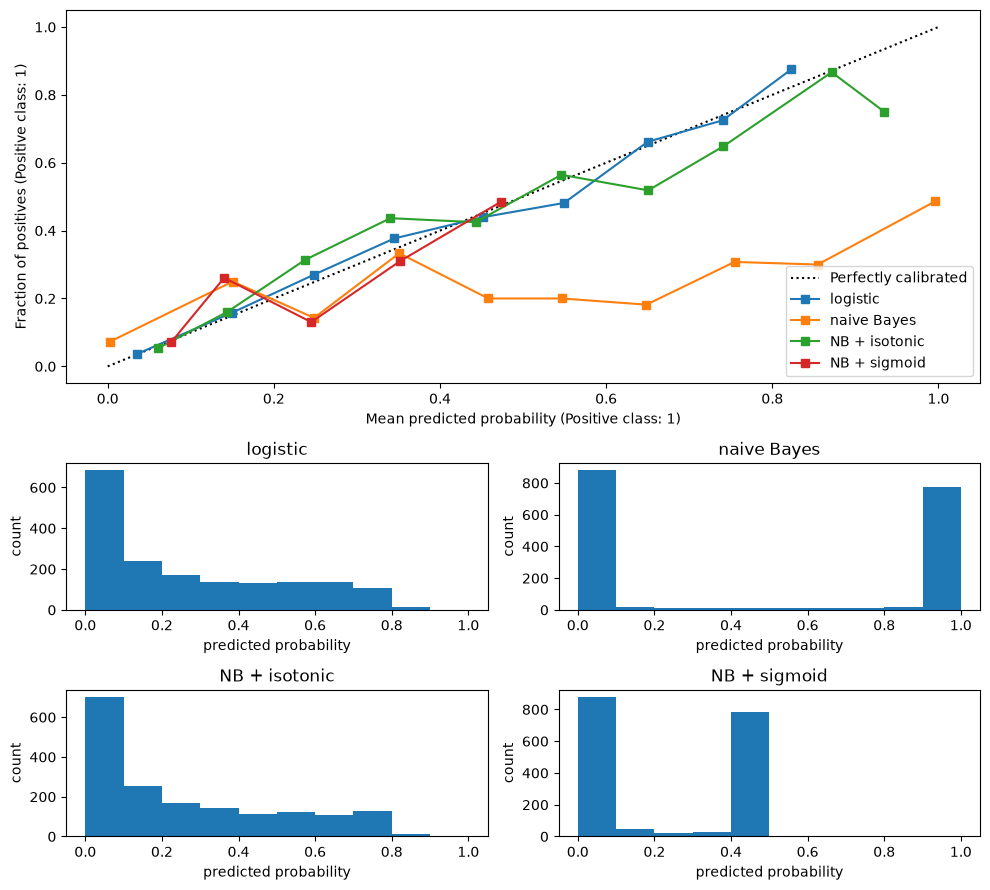

In [28]:
from matplotlib.gridspec import GridSpec
from sklearn.calibration import CalibrationDisplay

nb_sig = CalibratedClassifierCV(make_pipeline(pre, GaussianNB()), method="sigmoid", cv=5).fit(X_train, y_train)
models = [("logistic", logreg), ("naive Bayes", nb), ("NB + isotonic", nb_cal), ("NB + sigmoid", nb_sig)]
fig = plt.figure(figsize=(10, 9))
gs = GridSpec(4, 2)
ax_cal = fig.add_subplot(gs[:2, :2])
for name, m in models:
    CalibrationDisplay.from_predictions(y_test, m.predict_proba(X_test)[:, 1], n_bins=10, name=name, ax=ax_cal)
for (name, m), pos in zip(models, [(2, 0), (2, 1), (3, 0), (3, 1)]):
    ax = fig.add_subplot(gs[pos])
    ax.hist(m.predict_proba(X_test)[:, 1], range=(0, 1), bins=10)
    ax.set(title=name, xlabel="predicted probability", ylabel="count")
plt.tight_layout()
plt.show()

### What calibration changes and what it does not (depth: self-study or if time allows)

*Adapted from [Probability Calibration curves](https://scikit-learn.org/1.9/auto_examples/calibration/plot_calibration_curve.html) (scikit-learn developers, BSD-3-Clause).*

The table compares the four versions on probability metrics (Brier score, log loss), the ranking metric (ROC AUC) and the classification metrics at threshold 0.5. Calibration is a monotone transformation, so it should leave the ranking (AUC) almost unchanged; it improves the Brier score and the log loss, and it can change precision and recall at a fixed threshold, because the probabilities near 0.5 move.

In [29]:
from sklearn.metrics import f1_score, log_loss, precision_score, recall_score

rows = []
for name, m in models:
    q = m.predict_proba(X_test)[:, 1]
    p = (q >= 0.5).astype(int)
    rows.append({"model": name, "Brier": brier_score_loss(y_test, q), "log loss": log_loss(y_test, q),
                 "ROC AUC": roc_auc_score(y_test, q), "max p": q.max(), "precision": precision_score(y_test, p, zero_division=0),
                 "recall": recall_score(y_test, p), "F1": f1_score(y_test, p)})
pd.DataFrame(rows).set_index("model").round(3)

,Brier,log loss,ROC AUC,max p,precision,recall,F1
model,,,,,,,
logistic,0.138,0.418,0.844,0.851,0.626,0.531,0.575
naive Bayes,0.278,3.115,0.810,1.000,0.472,0.839,0.604
NB + isotonic,0.150,0.458,0.808,0.960,0.594,0.482,0.532
NB + sigmoid,0.154,0.468,0.805,0.477,0.000,0.000,0.000


Naive Bayes recalibrated with the sigmoid method never reaches a probability of 0.5 on the test set (see `max p`), so at the default threshold it flags nobody: its precision is reported as 0 and its recall is 0. Its probabilities are far better than before (Brier score), but a fixed threshold of 0.5 no longer makes sense for it. This is another reason to choose the threshold from costs.

**Sigmoid or isotonic?** Platt scaling fits a logistic curve with two parameters, so it can repair a curve that is too flat or too steep around the middle (typical for under-confident models) but not every shape. Isotonic regression is a free monotone step function: it can repair any monotone distortion, including the over-confidence of naive Bayes, but it needs more calibration data and can overfit with few cases (as a rule of thumb, more than about 1,000 is comfortable).

### Four churn models (depth: self-study or if time allows)

Which of our churn models can be trusted for a forecast? We compare logistic regression, 50-nearest neighbours and gradient boosting (Session 10; here a black box) by calibration curve, Brier score and the **expected number of churners** (the sum of the probabilities), against the 467 churners actually in the test set.

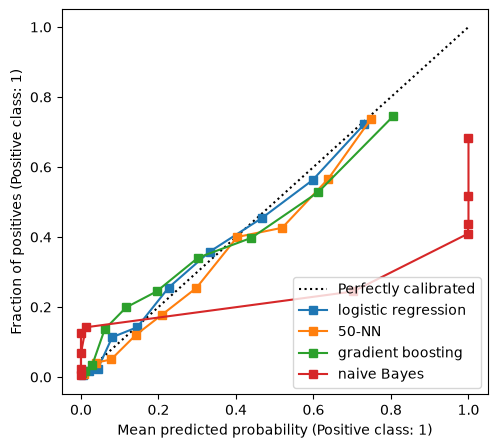

actual churners in the test set: 467


,ROC AUC,Brier,expected churners,cost with rule c / L
model,,,,
logistic regression,0.844,0.138,466.001,109200
50-NN,0.834,0.142,520.640,111500
gradient boosting,0.830,0.144,453.062,115500
naive Bayes,0.810,0.278,829.456,113700


In [30]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = make_pipeline(pre, HistGradientBoostingClassifier(random_state=0)).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(5.5, 5))
rows = []
for name, m in [("logistic regression", logreg), ("50-NN", knn), ("gradient boosting", hgb), ("naive Bayes", nb)]:
    q = m.predict_proba(X_test)[:, 1]
    CalibrationDisplay.from_predictions(y_test, q, n_bins=10, strategy="quantile", name=name, ax=ax)
    rows.append({"model": name, "ROC AUC": roc_auc_score(y_test, q), "Brier": brier_score_loss(y_test, q),
                 "expected churners": q.sum(), "cost with rule c / L": cost(y_test, q, OFFER / LOST)})
plt.show()
print("actual churners in the test set:", y_test.sum())
pd.DataFrame(rows).set_index("model").round(3)

Logistic regression is closest to the diagonal and expects almost exactly the true number of churners. 50-NN overestimates the number somewhat and gradient boosting underestimates it slightly; naive Bayes expects almost twice as many churners as there are. The cost of the rule *c / L* depends on the ranking as much as on the calibration, so it does not single out naive Bayes; the forecast does. Finance should get its forecast from a model whose expected number of churners matches reality on held-out data.

> 📖 **Read more:** [extras/11-calibration-curve.ipynb](extras/11-calibration-curve.ipynb) (scikit-learn gallery): calibration of naive Bayes and of a linear support vector classifier, whose curve has the opposite (under-confident) shape.

## 5 · Class imbalance and class weights

A classification problem is **imbalanced** when one class is much rarer than the other. A learning algorithm that minimises the average loss over all rows gains little by getting the rare rows right, so it predicts the frequent class most of the time. Fraud, machine failures, diseases, complaints and churn are all rare compared with normal cases. Accuracy hides the problem: "nobody churns" is right for 73.5 % of the Telco customers.

Three families of remedies change the *training*, never the data we evaluate on:

- **class weights** multiply the loss of every row of a class by a constant;
- **undersampling** deletes rows of the frequent class; **oversampling** duplicates or invents rows of the rare class (Section 6);
- or we leave the model alone and **move the threshold** (Section 3).

The common choice `class_weight="balanced"` gives class *c* the weight w_c = n / (K · n_c), with *n* rows, *K* classes and *n_c* rows in class *c*, so that every class contributes the same total weight. For the Telco data (n = 7,043, 1,869 churners): churners get 7,043 / (2 · 1,869) = 1.88, loyal customers 7,043 / (2 · 5,174) = 0.68. A weight of 1.88 acts like 1.88 copies of the row, but needs no extra rows, no randomness and no new library.

For the comparisons of Sections 5 and 6 we use all 7,043 customers with stratified 5-fold cross-validation and out-of-fold predictions. `compute_class_weight("balanced", ...)` shows the weights; `class_weight="balanced"` in `LogisticRegression` uses them. The helper `report` prints accuracy, recall of churners and macro-F1.

In [31]:
from sklearn.metrics import accuracy_score
from sklearn.utils.class_weight import compute_class_weight

print(compute_class_weight("balanced", classes=np.array([0, 1]), y=y).round(3))


def report(name, pred):
    print(f"{name:20s} accuracy {accuracy_score(y, pred):.3f}  recall of churners {recall_score(y, pred):.3f}  "
          f"macro-F1 {f1_score(y, pred, average='macro'):.3f}")


report("nobody churns", np.zeros(len(y), dtype=int))
plain = make_pipeline(pre, LogisticRegression(max_iter=2000))
report("logistic regression", cross_val_predict(plain, X, y, cv=cv))
weighted = make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight="balanced"))
report("balanced weights", cross_val_predict(weighted, X, y, cv=cv))

[0.681 1.884]
nobody churns        accuracy 0.735  recall of churners 0.000  macro-F1 0.424
logistic regression  accuracy 0.804  recall of churners 0.549  macro-F1 0.734


balanced weights     accuracy 0.748  recall of churners 0.804  macro-F1 0.719


With balanced weights the model finds about 80 % of the churners instead of about 55 %, but its accuracy drops by about 5 points: more churners are found at the price of many more false alarms. Weights are not a free improvement; they must be validated like any other setting.

> **Note.** Before correcting imbalance, ask whether the rare class matters for the decision. If you need calibrated probabilities, for example to forecast the number of churners, any correction distorts them (van den Goorbergh et al., 2022). Then fit without correction and choose the threshold from the costs instead.

### Accuracy and macro-F1 with three classes (depth: self-study or if time allows)

With several classes the effect is spread over a tail of rare classes. Worked example with 100 cases (80 of A, 15 of B, 5 of C) and the rule "always A":

| | precision | recall | F1 |
|---|---|---|---|
| A | 80/100 = 0.80 | 80/80 = 1.00 | 0.89 |
| B | not defined (never predicted) | 0/15 = 0 | 0 |
| C | not defined | 0/5 = 0 | 0 |

Accuracy is 0.80, macro-F1 is 0.89 / 3 = 0.30. Session 13 meets a task with hundreds of classes, most of them rare.

### Weights that express costs (depth: self-study or if time allows)

Weights need not be "balanced". If missing a churner costs four times as much as a wasted offer (€400 against €100), a weight ratio of 4 : 1 tells the model exactly that. `class_weight={0: 1, 1: 4}` sets the weights by hand. For a calibrated model, this weighting moves the implicit threshold to about c / L = 0.25, so the result is close to the cost-tuned threshold of Section 3 (Elkan, 2001).

In [32]:
cost_weighted = make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight={0: 1, 1: LOST / OFFER}))
oof_plain = cross_val_predict(plain, X, y, cv=cv, method="predict_proba")[:, 1]
oof_costw = cross_val_predict(cost_weighted, X, y, cv=cv, method="predict_proba")[:, 1]
print("weights 1:4, threshold 0.5   cost per customer", round(cost(y, oof_costw, 0.5) / len(y), 1))
print("no weights, threshold 0.25   cost per customer", round(cost(y, oof_plain, 0.25) / len(y), 1))
print("no weights, threshold 0.5    cost per customer", round(cost(y, oof_plain, 0.5) / len(y), 1))

weights 1:4, threshold 0.5   cost per customer 63.3
no weights, threshold 0.25   cost per customer 62.4
no weights, threshold 0.5    cost per customer 70.1


### Weighted models give shifted probabilities (depth: self-study or if time allows)

Class weights change the probabilities, not the ranking. A model trained with balanced weights ranks customers as well as the unweighted one, but believes that far more of them will churn. The rule *p > c / L* applied to its probabilities then flags too many customers. Recalibration on held-out folds (Section 4) repairs the probabilities; a threshold tuned on costs also compensates, because it looks at the costs, not at the probabilities.

In [33]:
weighted.fit(X_train, y_train)
weighted_cal = CalibratedClassifierCV(make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight="balanced")),
                                      method="sigmoid", cv=5).fit(X_train, y_train)
for name, m in [("logistic regression", logreg), ("class weights", weighted), ("class weights, recalibrated", weighted_cal)]:
    q = m.predict_proba(X_test)[:, 1]
    print(f"{name:28s} AUC {roc_auc_score(y_test, q):.3f}  Brier {brier_score_loss(y_test, q):.3f}  "
          f"expected churners {q.sum():4.0f}  cost at c/L {cost(y_test, q, OFFER / LOST)}")
print("actual churners:", y_test.sum())

logistic regression          AUC 0.844  Brier 0.138  expected churners  466  cost at c/L 109200
class weights                AUC 0.844  Brier 0.165  expected churners  725  cost at c/L 116400
class weights, recalibrated  AUC 0.844  Brier 0.138  expected churners  465  cost at c/L 108700
actual churners: 467


### When churn is much rarer (depth: self-study or if time allows)

*Adapted from [Fitting model on imbalanced datasets and how to fight bias](https://imbalanced-learn.org/stable/auto_examples/applications/plot_impact_imbalanced_classes.html) (Guillaume Lemaître, imbalanced-learn, MIT), which does the same on the adult census data.*

At 26.5 % churn the imbalance is mild. To see what happens with a rarer positive class, `make_imbalance` keeps all loyal customers but only one churner for every 19 of them (about 5 % churn). We compare a dummy model, logistic regression and a random forest, each with and without balanced weights, and imbalanced-learn's `BalancedRandomForestClassifier`, which undersamples the majority class separately for every tree. **Balanced accuracy** (the mean recall of the two classes) is the metric, because plain accuracy would reward the dummy.

In [34]:
from imblearn.datasets import make_imbalance
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.dummy import DummyClassifier

X_rare, y_rare5 = make_imbalance(X, y, sampling_strategy={1: (y == 0).sum() // 19}, random_state=0)
print(y_rare5.value_counts().to_dict(), "churn share", round(y_rare5.mean(), 3))


def forest(**kw):
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=2, random_state=0, n_jobs=-1, **kw)


rare_models = {
    "dummy": DummyClassifier(strategy="most_frequent"),
    "logistic regression": make_pipeline(pre, LogisticRegression(max_iter=2000)),
    "logistic, balanced weights": make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight="balanced")),
    "random forest": make_pipeline(pre, forest()),
    "random forest, balanced weights": make_pipeline(pre, forest(class_weight="balanced")),
    "balanced random forest": make_pipeline(pre, BalancedRandomForestClassifier(
        n_estimators=200, sampling_strategy="all", replacement=True, bootstrap=False, random_state=0, n_jobs=-1)),
}

{0: 5174, 1: 272} churn share 0.05


`cross_validate(model, X, y, scoring=["accuracy", "balanced_accuracy"])` returns both metrics per fold; we keep the means.

In [35]:
rows = []
for name, m in rare_models.items():
    r = cross_validate(m, X_rare, y_rare5, cv=cv, scoring=["accuracy", "balanced_accuracy"])
    rows.append({"model": name, "accuracy": r["test_accuracy"].mean(), "balanced accuracy": r["test_balanced_accuracy"].mean()})
pd.DataFrame(rows).set_index("model").round(3)

,accuracy,balanced accuracy
model,,
dummy,0.950,0.500
logistic regression,0.950,0.500
"logistic, balanced weights",0.739,0.767
random forest,0.951,0.528
"random forest, balanced weights",0.901,0.666
balanced random forest,0.812,0.758


At 5 % churn the dummy is 95 % accurate. The unweighted logistic regression has the same accuracy and the same balanced accuracy of 0.5: it has learned to predict "nobody churns". The unweighted forest is hardly better. Balanced weights help the linear model a lot. For the random forest, `class_weight` helps much less, because a forest grown to small leaves can still fit the majority class; the balanced random forest, which undersamples inside each tree, does much better. The lesson of the imbalanced-learn example carries over: the right remedy depends on the model.

## 6 · Resampling inside the cross-validation with imbalanced-learn

**Resampling** changes the class proportions of the *training* data before the model is fitted:

- **random undersampling** deletes randomly chosen loyal customers until both classes are equally large (1,869 + 1,869 rows): faster training, but information is thrown away;
- **random oversampling** duplicates randomly chosen churners until both classes are equally large (5,174 + 5,174 rows): all information kept, but repeated rows tempt flexible models to memorise them;
- **SMOTE** (Synthetic Minority Over-sampling Technique; Chawla et al., 2002) creates *new* churners on the line between a churner and one of its nearest churner neighbours.

Resampling is part of *training*. It must be applied to the training folds only, never to a validation fold or the test set, for two reasons:

1. **The validation data must look like reality.** Real customers churn at 26.5 %; a balanced validation set makes every alarm look twice as likely to be right.
2. **Oversampling before splitting leaks.** If a copy of a row lands in the training fold and the original in the validation fold, the model is tested on a row it has seen.

```mermaid
flowchart LR
    subgraph wrong["Wrong: resample first"]
        w1["All training data"] --> w2["Oversample"] --> w3["Split into folds"] --> w4["Copies in train<br/>and validation fold"]
    end
    subgraph right["Right: resample inside each fold"]
        r1["All training data"] --> r2["Split into folds"] --> r3["Oversample the<br/>training folds only"] --> r4["Validate on<br/>untouched fold"]
    end
```

scikit-learn's `Pipeline` cannot hold a sampler, because a sampler changes the number of rows. The **imbalanced-learn** library (Lemaître, Nogueira & Aridas, 2017) provides its own `Pipeline` that calls a sampler's `fit_resample` **only during `fit`** and skips it during `predict` and `score`. Inside `cross_validate` or `GridSearchCV`, every training fold is resampled and every validation fold stays untouched.

First the samplers on their own. They have `fit_resample(X, y)` instead of `transform`, so they cannot be applied to test data by accident. `Counter` counts the classes after resampling.

In [36]:
from collections import Counter

from imblearn.over_sampling import SMOTE, SMOTENC, RandomOverSampler
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler

X_filled = X.fillna({"TotalCharges": 0})                    # samplers need complete data
for sampler in [RandomUnderSampler(random_state=0), RandomOverSampler(random_state=0)]:
    X_res, y_res = sampler.fit_resample(X_filled, y)
    print(f"{type(sampler).__name__:19s}", dict(Counter(y_res)))

RandomUnderSampler  {0: 1869, 1: 1869}
RandomOverSampler   {0: 5174, 1: 5174}


**Predict before running.** We oversample *before* cross-validating a random forest, then do it properly inside an imbalanced-learn pipeline. Which F1 will be higher, and which one is honest?

In [37]:
from sklearn.model_selection import cross_val_score

X_dummies = pd.get_dummies(X_filled, dtype=int)                       # the forest needs numbers
rf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
X_over, y_over = RandomOverSampler(random_state=0).fit_resample(X_dummies, y)       # WRONG: before the split
wrong = cross_val_score(rf, X_over, y_over, cv=cv, scoring="f1").mean()
right = cross_val_score(make_imb_pipeline(RandomOverSampler(random_state=0), rf),   # RIGHT: inside each fold
                        X_dummies, y, cv=cv, scoring="f1").mean()
print("oversampled before CV", round(wrong, 3), "| inside the pipeline", round(right, 3))

oversampled before CV 0.899 | inside the pipeline 0.577


The first number is an illusion: the forest recognises copies of churners it has seen in training. Santos et al. (2018) found this mistake in published studies.

Now the comparison for the churn model. Five strategies, each in an imbalanced-learn pipeline, plus the alternative of Section 3: no correction, but a lower threshold (0.3). `cross_val_predict(..., method="predict_proba")` resamples only the training folds.

In [38]:
def lr(class_weight=None):
    return LogisticRegression(max_iter=2000, class_weight=class_weight)


candidates = {
    "no correction": make_imb_pipeline(pre, lr()),
    "undersampling": make_imb_pipeline(pre, RandomUnderSampler(random_state=0), lr()),
    "oversampling": make_imb_pipeline(pre, RandomOverSampler(random_state=0), lr()),
    "SMOTE": make_imb_pipeline(pre, SMOTE(random_state=0), lr()),
    "class weights": make_imb_pipeline(pre, lr("balanced")),
}
probas = {name: cross_val_predict(m, X, y, cv=cv, method="predict_proba")[:, 1] for name, m in candidates.items()}

The helper `scores` evaluates the out-of-fold probabilities at a threshold: classification metrics at that threshold, ranking metrics (ROC AUC, PR AUC) over all thresholds.

In [39]:
def scores(proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred), "recall": recall_score(y, pred),
            "F1": f1_score(y, pred), "ROC AUC": roc_auc_score(y, proba), "PR AUC": average_precision_score(y, proba)}


table = pd.DataFrame({name: scores(p) for name, p in probas.items()}).T
table.loc["no correction, threshold 0.3"] = scores(probas["no correction"], 0.3)
table.round(3)

,accuracy,precision,recall,F1,ROC AUC,PR AUC
no correction,0.804,0.656,0.549,0.598,0.845,0.653
undersampling,0.747,0.515,0.804,0.628,0.844,0.644
oversampling,0.747,0.514,0.805,0.628,0.845,0.651
SMOTE,0.754,0.524,0.800,0.633,0.844,0.652
class weights,0.748,0.516,0.804,0.628,0.845,0.651
"no correction, threshold 0.3",0.766,0.541,0.769,0.636,0.845,0.653


An honest result. Every correction does what it promises: the recall of churners rises from about 0.55 to about 0.80, at the price of precision and accuracy. But ROC AUC and PR AUC hardly change: the corrections do not make the model *rank* customers better, they only move the point at which it says "churn". Lowering the threshold of the uncorrected model reaches the same region without resampling, without invented customers and with probabilities that keep their meaning. SMOTE is not better than simply copying churners. The bar chart shows the trade-off.

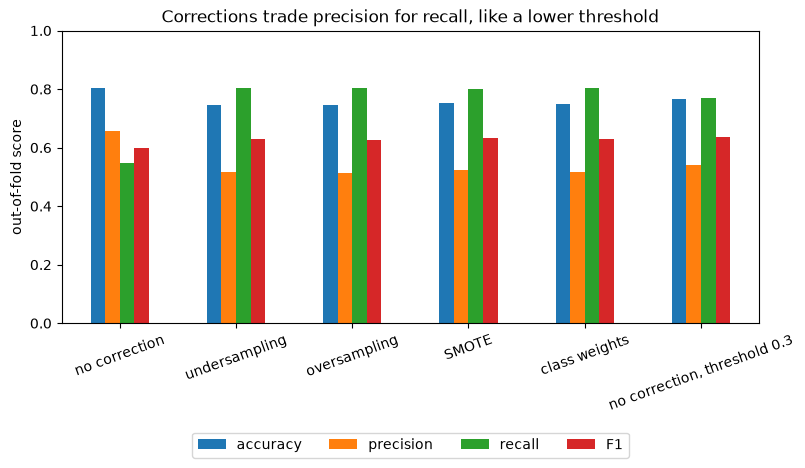

In [40]:
ax = table[["accuracy", "precision", "recall", "F1"]].plot.bar(figsize=(9, 3.8), rot=20)
ax.set(ylabel="out-of-fold score", ylim=(0, 1), title="Corrections trade precision for recall, like a lower threshold")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.35))
plt.show()

> **Note.** Report per-class precision and recall next to F1. "With class weights we find 80 % of the churners instead of 55 %, but only about half of the customers we call would have left" tells a retention team what the model does; "F1 rose by 0.03" does not.

> 📖 **Read more:** [extras/12-imbalanced-classes-impact.ipynb](extras/12-imbalanced-classes-impact.ipynb) and [extras/13-imblearn-pipeline.ipynb](extras/13-imblearn-pipeline.ipynb) (imbalanced-learn examples): every remedy on the adult census data, and a pipeline that chains PCA, a cleaning sampler, SMOTE and k-NN.

### SMOTE step by step (depth: self-study or if time allows)

*Adapted from [Sample generator used in SMOTE-like samplers](https://imbalanced-learn.org/stable/auto_examples/over-sampling/plot_illustration_generation_sample.html) (Guillaume Lemaître, imbalanced-learn, MIT).*

For each new row SMOTE

1. picks a minority row **x**,
2. finds its *k* nearest minority neighbours (default *k* = 5) and picks one of them, **x_nn**,
3. places the new row at a random point on the line between them: **x_new = x + λ · (x_nn − x)**, with λ drawn uniformly between 0 and 1.

Worked example in two features: x = (2, 3), x_nn = (4, 7), λ = 0.25 gives x_new = (2 + 0.25 · 2, 3 + 0.25 · 4) = (2.5, 4.0). The next cell draws the construction on simulated points: one chosen minority row, its five nearest minority neighbours, and one synthetic row on each connecting line.

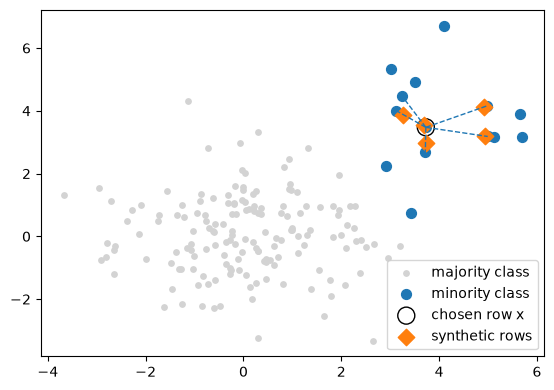

In [41]:
rng = np.random.default_rng(3)
majority = rng.normal([0, 0], 1.3, size=(160, 2))
minority = rng.normal([4.2, 3.8], 1.0, size=(14, 2))
i = int(np.argmin(np.linalg.norm(minority - minority.mean(axis=0), axis=1)))
nn = np.argsort(np.linalg.norm(minority - minority[i], axis=1))[1:6]
synthetic = np.array([minority[i] + rng.uniform() * (minority[j] - minority[i]) for j in nn])
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(*majority.T, s=15, color="lightgrey", label="majority class")
ax.scatter(*minority.T, s=50, color="tab:blue", label="minority class")
for j in nn:
    ax.plot(*np.c_[minority[i], minority[j]], "--", color="tab:blue", lw=1)
ax.scatter(*minority[i], s=150, facecolor="none", edgecolor="black", label="chosen row x")
ax.scatter(*synthetic.T, s=70, marker="D", color="tab:orange", label="synthetic rows")
ax.legend(loc="lower right")
plt.show()

Synthetic rows fill the region of the minority class instead of stacking copies on single points. Because SMOTE uses distances, scale the numeric features first (it sits after the `ColumnTransformer` in the pipeline above). It needs at least *k* + 1 rows per class: with `k_neighbors=5`, a class with 5 rows or fewer raises an error, which matters in tasks with many rare classes.

> **Note.** SMOTE invents data. In high dimensions (thousands of text columns) "between two neighbours" has little meaning, and synthetic rows can fall into regions of another class. Elor and Averbuch-Elor (2022) compared balancing methods across many datasets and found that strong classifiers rarely profit from them compared with tuning the threshold.

### SMOTENC for mixed tables (depth: self-study or if time allows)

*Adapted from [Compare over-sampling samplers](https://imbalanced-learn.org/stable/auto_examples/over-sampling/plot_comparison_over_sampling.html) (Guillaume Lemaître, imbalanced-learn, MIT).*

Plain `SMOTE` needs numbers. Applied after one-hot encoding (as above) it creates rows with fractional 0/1 values such as "0.3 of a fibre-optic contract". `SMOTENC` interpolates only the numeric columns and gives each synthetic row the most frequent category among its neighbours; `SMOTEN` is the version for purely categorical data. Next we create invented churners from the raw table and look at the last one.

In [42]:
X_sm, y_sm = SMOTENC(categorical_features=categorical, random_state=0).fit_resample(X_filled, y)
print(dict(Counter(y_sm)), "|", len(X_sm) - len(X), "invented customers")
print(X_sm.iloc[-1][["tenure", "MonthlyCharges", "TotalCharges", "Contract", "InternetService"]].to_dict())

{0: 5174, 1: 5174} | 3305 invented customers
{'tenure': 2, 'MonthlyCharges': 51.71280497052741, 'TotalCharges': 96.27027965110739, 'Contract': 'Month-to-month', 'InternetService': 'DSL'}


The invented customer is a plausible combination: an interpolated tenure (rounded to whole months, because the column holds integers) and interpolated charges, with categories taken from real churners. Look closely, though: for real customers `TotalCharges` is roughly tenure times `MonthlyCharges`, and for invented ones this need not hold, because each column is interpolated on its own. Synthetic rows do not respect the rules that tie columns together.

### Partial ratios, and tuning the sampler (depth: self-study or if time allows)

*Adapted from the course's earlier class-imbalance notebook and the imbalanced-learn user guide.*

Full balancing is not the only option. `sampling_strategy=0.5` raises the churners to half the number of loyal customers; for several classes a dictionary such as `{class: max(count, 20)}` lifts every rare class to at least 20 rows. Because the sampler is a pipeline step, its settings can be tuned like any hyperparameter: the parameter name is the step name (`randomoversampler`), two underscores, and the parameter.

In [43]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(make_imb_pipeline(pre, RandomOverSampler(random_state=0), lr()),
                      {"randomoversampler__sampling_strategy": [0.4, 0.6, 0.8, 1.0]},
                      scoring="f1", cv=cv).fit(X_train, y_train)
print(pd.DataFrame(search.cv_results_)[["param_randomoversampler__sampling_strategy", "mean_test_score"]].round(3).to_string(index=False))

 param_randomoversampler__sampling_strategy  mean_test_score
                                        0.4            0.612
                                        0.6            0.631
                                        0.8            0.635
                                        1.0            0.630


F1 changes little between ratios of 0.6 and 1.0. Tuning the ratio for F1 is, in effect, tuning a threshold by another route: a higher ratio makes the model say "churn" more often.

### SMOTE variants and ADASYN on toy data (depth: self-study or if time allows)

*Adapted from [Compare over-sampling samplers](https://imbalanced-learn.org/stable/auto_examples/over-sampling/plot_comparison_over_sampling.html) (Guillaume Lemaître, imbalanced-learn, MIT).*

On two-dimensional toy data we can see how samplers move a decision boundary. `make_classification` creates three classes with 5 %, 25 % and 70 % of the rows. We compare a logistic regression without resampling with random oversampling, SMOTE, **ADASYN** (which creates more synthetic rows near the points that are hard to classify with a nearest-neighbour rule) and **Borderline-SMOTE** (which only uses minority rows close to the border between classes).

In [44]:
from imblearn.over_sampling import ADASYN, BorderlineSMOTE
from sklearn.datasets import make_classification

Xt, yt = make_classification(n_samples=300, n_features=2, n_informative=2, n_redundant=0, n_repeated=0,
                             n_classes=3, n_clusters_per_class=1, weights=[0.05, 0.25, 0.7], class_sep=0.8,
                             random_state=0)
toy = {"no resampling": LogisticRegression(),
       "random oversampling": make_imb_pipeline(RandomOverSampler(random_state=0), LogisticRegression()),
       "SMOTE": make_imb_pipeline(SMOTE(random_state=0), LogisticRegression()),
       "ADASYN": make_imb_pipeline(ADASYN(random_state=0), LogisticRegression()),
       "Borderline-SMOTE": make_imb_pipeline(BorderlineSMOTE(random_state=0), LogisticRegression())}
print({int(k): v for k, v in sorted(Counter(yt).items())})

{0: 16, 1: 74, 2: 210}


`DecisionBoundaryDisplay` (Block 1) colours the plane by the predicted class for each model; the points use the same colours for their true class. `disp.multiclass_colors_` returns the colours the display used.

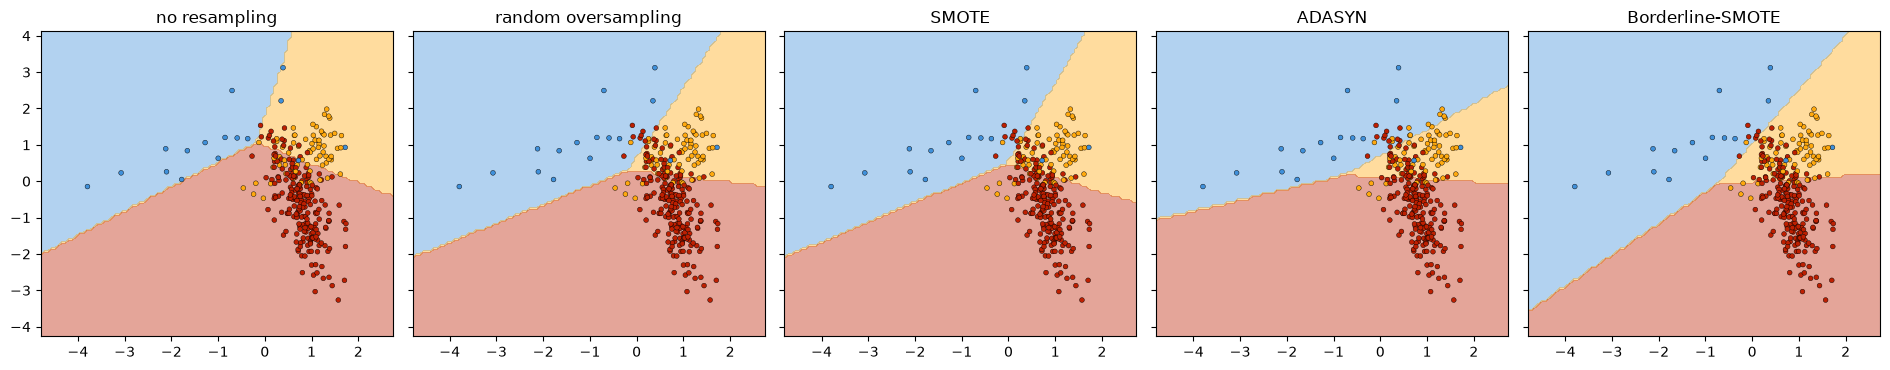

In [45]:
from sklearn.inspection import DecisionBoundaryDisplay

fig, axes = plt.subplots(1, 5, figsize=(19, 3.8), sharey=True)
from matplotlib.colors import ListedColormap

for ax, (name, m) in zip(axes, toy.items()):
    m.fit(Xt, yt)
    disp = DecisionBoundaryDisplay.from_estimator(m, Xt, response_method="predict", alpha=0.4, ax=ax)
    ax.scatter(Xt[:, 0], Xt[:, 1], c=yt, cmap=ListedColormap(disp.multiclass_colors_), s=12, edgecolor="k", lw=0.3)
    ax.set_title(name)
plt.tight_layout()
plt.show()

The smallest class (blue) is well separated and gets its own region in every panel. The interesting part is the overlap of the middle class (orange, 25 %) with the majority (red, 70 %). Without resampling, many orange points sit in the red region. Every sampler moves the boundaries so that the smaller classes get more room; the panels differ in where that room comes from, and ADASYN, which concentrates synthetic rows where the classes overlap, gives the middle class the widest region.

### Cleaning and selecting undersamplers (depth: self-study or if time allows)

*Adapted from [Compare under-sampling samplers](https://imbalanced-learn.org/stable/auto_examples/under-sampling/plot_comparison_under_sampling.html) (Guillaume Lemaître, imbalanced-learn, MIT).*

Random undersampling deletes majority rows blindly. Other undersamplers choose which rows to remove:

- **NearMiss** keeps the majority rows that are closest to minority rows (version 1 by average distance to the nearest minority rows), focusing the model on the border;
- **Tomek links** are pairs of nearest neighbours from different classes; removing their majority member cleans the border;
- **Edited nearest neighbours** (ENN) removes majority rows whose neighbours mostly belong to another class;
- **ClusterCentroids** replaces the majority class by the centres of k-means clusters (prototype generation rather than selection).

The cell compares the class counts after each method on the toy data.

In [46]:
from imblearn.under_sampling import ClusterCentroids, EditedNearestNeighbours, NearMiss, TomekLinks

for sampler in [RandomUnderSampler(random_state=0), NearMiss(version=1), TomekLinks(),
                EditedNearestNeighbours(), ClusterCentroids(random_state=0)]:
    _, y_s = sampler.fit_resample(Xt, yt)
    print(f"{type(sampler).__name__:24s}", {int(k): v for k, v in sorted(Counter(y_s).items())})

RandomUnderSampler       {0: 16, 1: 16, 2: 16}
NearMiss                 {0: 16, 1: 16, 2: 16}
TomekLinks               {0: 16, 1: 56, 2: 192}
EditedNearestNeighbours  {0: 16, 1: 36, 2: 162}
ClusterCentroids         {0: 16, 1: 16, 2: 16}


The selection methods (random, NearMiss, ClusterCentroids) shrink the majority classes to the size of the smallest class. The cleaning methods (Tomek links, ENN) remove only a few rows near the borders and leave the imbalance largely in place; they are often combined with oversampling (`SMOTETomek`, `SMOTEENN`).

> 📖 **Read more:** [extras/14-smote-sample-generation.ipynb](extras/14-smote-sample-generation.ipynb), [extras/15-over-sampling-comparison.ipynb](extras/15-over-sampling-comparison.ipynb) and [extras/16-under-sampling-comparison.ipynb](extras/16-under-sampling-comparison.ipynb) (imbalanced-learn examples): all samplers with their decision boundaries and resampled data.

## Worked example · Which strategy is cheapest for the retention team?

Section 6 compared the strategies by precision, recall and F1. The retention team pays in euros: €100 per offer and €400 per lost churner. We price every strategy at the default threshold 0.5, using the out-of-fold probabilities of Section 6, and compare with the uncorrected logistic regression whose threshold `TunedThresholdClassifierCV` chooses from these costs inside each training fold. `cross_val_predict(tuned_model, X, y, cv=cv)` keeps that honest: each customer is predicted with a threshold chosen without them.

In [47]:
rows = [{"strategy": name, "offers": int((p >= 0.5).sum()), "cost €": cost(y, p, 0.5)} for name, p in probas.items()]
tuned_strategy = TunedThresholdClassifierCV(candidates["no correction"], scoring=make_scorer(gain), cv=5, random_state=0)
pred_tuned = cross_val_predict(tuned_strategy, X, y, cv=cv)
rows.append({"strategy": "no correction, cost-tuned threshold", "offers": int(pred_tuned.sum()), "cost €": -gain(y, pred_tuned)})
cost_table = pd.DataFrame(rows).sort_values("cost €")
cost_table["cost per customer €"] = (cost_table["cost €"] / len(y)).round(1)
cost_table

,strategy,offers,cost €,cost per customer €
3,SMOTE,2855,435100,61.8
4,class weights,2911,437900,62.2
1,undersampling,2915,438300,62.2
2,oversampling,2924,438400,62.2
5,"no correction, cost-tuned threshold",3020,439600,62.4
0,no correction,1564,493600,70.1


A team that can only call a fixed number of customers asks a different question: how many of the 1,000 customers with the highest predicted risk are real churners? Because the corrections hardly change the ranking, the answer is nearly the same for every strategy.

In [48]:
for name in ["no correction", "SMOTE", "class weights"]:
    top = np.argsort(-probas[name])[:1000]
    print(f"{name:14s} precision among the top 1,000: {y.iloc[top].mean():.3f}")

no correction  precision among the top 1,000: 0.711
SMOTE          precision among the top 1,000: 0.709
class weights  precision among the top 1,000: 0.719


**Recommendation for the retention team.** With an offer at €100 and a lost customer at €400, every correction and the cost-tuned threshold cost about the same and clearly less than the uncorrected model at 0.5. The cost-tuned threshold is the simplest to explain and to adapt: if the value of a lost customer changes, only the threshold moves (exercise 2.5 shows what happens at €1,000), and the probabilities stay calibrated for Finance's forecast. Resampling adds a step, invents or discards customers and distorts the probabilities, without ranking customers any better.

## Check your understanding

1. Explain the meaning of AUC = 0.84 in one sentence without using the word "curve".
2. For a fraud model with 0.1 % positives, why can ROC AUC be 0.98 while precision at 50 % recall is only 0.10?
3. A retention offer costs €50 and a lost customer costs €500. Which threshold follows from *p > c / L*, and which assumption does this rule make?
4. Why did oversampling before cross-validation give a much higher F1 than oversampling inside the pipeline?
5. A model trained with `class_weight="balanced"` predicts far more churners than there are. Is its ROC AUC necessarily worse than that of the unweighted model? What happens if you apply *p > c / L* to its probabilities?

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. Answer *Paper* and *Predict* tasks in the markdown cell below the task before running any code, *Class* tasks together, *Code* tasks in the empty code cells. The variables of this notebook (`X_train`, `y_train`, `cv`, `pre`, `cost`, `OFFER`) are available.

### 2.1 · 99 % accuracy

*Paper · 5 min*

> 1 % of card transactions are fraud. A model that always says "no fraud" scores 99 % accuracy. Is it a good model? Name three numbers from this block that expose it, and give their values for this model.

*Source:* [Accuracy paradox, Wikipedia](https://en.wikipedia.org/wiki/Accuracy_paradox)

*Your answer:*

### 2.2 · AUC by counting pairs

*Paper · 10 min*

> Three churners with scores 0.8, 0.6 and 0.3, and three stayers with scores 0.7, 0.4 and 0.2. What share of churner–stayer pairs is ranked correctly? That share is the AUC.

*Source:* [Hanley & McNeil (1982), "The meaning and use of the area under a ROC curve", *Radiology*](https://doi.org/10.1148/radiology.143.1.7063747) (ties count ½); the six scores are an original example for this course

*Your answer:*

### 2.3 · Threshold from money

*Paper · 10 min*

> A retention offer costs €20 and keeps a churner half the time; a lost customer costs €200. From which churn probability is the offer worth it?

*Source:* [Elkan (2001), "The foundations of cost-sensitive learning", IJCAI](https://cseweb.ucsd.edu/~elkan/rescale.pdf)

*Your answer:*

### 2.4 · How calibrated are you?

*Class · 15 min*

> Ten questions about Berlin, such as "Is Berlin larger in area than Paris?". Each student answers and states a confidence from 50 % to 100 %. Plot the class's calibration curve.

*Source:* [Overconfidence effect, Wikipedia](https://en.wikipedia.org/wiki/Overconfidence_effect)

*Your answer:*

### 2.5 · Half-balanced, and a more valuable customer

*Code · 25 min*

> Put the preprocessing step `pre`, a sampler and a `LogisticRegression(max_iter=2000)` in an imbalanced-learn pipeline (`from imblearn.pipeline import make_pipeline`).
>
> (1) Compare `RandomOverSampler(sampling_strategy=0.5)` (churners raised to half the loyal customers) with full balancing (`sampling_strategy=1.0`) and with no sampler: precision, recall and F1 of the churners with out-of-fold predictions (`cross_val_predict` on the training data with `cv`).
> (2) A lost customer is now worth €1,000 instead of €400; an offer still costs €100. Compute the campaign cost of each model at threshold 0.5 on the out-of-fold predictions, and the cost of the uncorrected model at the threshold c / L. Which wins now?

*Source:* original exercise for this course; background: [imbalanced-learn: Common pitfalls and recommended practices](https://imbalanced-learn.org/stable/common_pitfalls.html)

### 2.6 · Say what the correction does

*Pairs · 5 min · Stretch*

> For each strategy of 2.5, write one sentence in the form "recall of churners rose from … to …, precision fell from … to …, the campaign cost changed by …". Which sentence would you show the retention team?

*Source:* original exercise for this course

*Your answer:*

## Debrief (15 min)

- **2.2:** compare a pair that counted 6 of 9 with one that counted ties or forgot a pair; the share of correctly ranked pairs is exactly what `roc_auc_score` computes.
- **2.3:** compare a solution that forgets the 50 % success rate of the offer (and gets 0.1) with the correct one; the success rate belongs in the formula *c / (s · L)*.
- **2.4:** show the class's calibration curve next to the naive Bayes curve of Section 4; people, like some models, tend to be over-confident.
- **2.5:** check that the sampler sits inside the pipeline and that costs were computed on out-of-fold predictions, not on the test set. Ask why balancing and the threshold *c / L* land close together at €400 but not at €1,000.
- **Bridge to Session 9.** The models so far used the columns as they came. Session 9 builds new inputs (dates, interactions, aggregates, target encodings) inside the same pipelines, without leakage.

## Further reading

- scikit-learn developers. *Tuning the decision threshold for class prediction*, *Probability calibration* and *Metrics and scoring*. https://scikit-learn.org/stable/modules/classification_threshold.html · https://scikit-learn.org/stable/modules/calibration.html · https://scikit-learn.org/stable/modules/model_evaluation.html
- imbalanced-learn developers. *Common pitfalls and recommended practices*. https://imbalanced-learn.org/stable/common_pitfalls.html
- Chawla, N. V., Bowyer, K. W., Hall, L. O. & Kegelmeyer, W. P. (2002). SMOTE: synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research*, 16, 321–357. https://doi.org/10.1613/jair.953
- Elkan, C. (2001). The foundations of cost-sensitive learning. *Proceedings of IJCAI 2001*, 973–978. https://cseweb.ucsd.edu/~elkan/rescale.pdf
- Elor, Y. & Averbuch-Elor, H. (2022). To SMOTE, or not to SMOTE? arXiv:2201.08528. https://arxiv.org/abs/2201.08528
- Hanley, J. A. & McNeil, B. J. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology*, 143(1), 29–36. https://doi.org/10.1148/radiology.143.1.7063747
- Lemaître, G., Nogueira, F. & Aridas, C. K. (2017). Imbalanced-learn: a Python toolbox to tackle the curse of imbalanced datasets in machine learning. *JMLR*, 18(17), 1–5. https://jmlr.org/papers/v18/16-365.html
- Niculescu-Mizil, A. & Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of ICML 2005*. https://doi.org/10.1145/1102351.1102430
- Saito, T. & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*, 10(3), e0118432. https://doi.org/10.1371/journal.pone.0118432
- Santos, M. S., Soares, J. P., Abreu, P. H., Araújo, H. & Santos, J. (2018). Cross-validation for imbalanced datasets: avoiding overoptimistic and overfitting approaches. *IEEE Computational Intelligence Magazine*, 13(4), 59–76. https://doi.org/10.1109/MCI.2018.2866730
- van den Goorbergh, R., van Smeden, M., Timmerman, D. & Van Calster, B. (2022). The harm of class imbalance corrections for risk prediction models. *JAMIA*, 29(9), 1525–1534. https://doi.org/10.1093/jamia/ocac093
- Van Calster, B., McLernon, D. J., van Smeden, M., Wynants, L. & Steyerberg, E. W. (2019). Calibration: the Achilles heel of predictive analytics. *BMC Medicine*, 17, 230. https://doi.org/10.1186/s12916-019-1466-7
- Extras of this block: [06](extras/06-classification-metrics.ipynb), [07](extras/07-roc-curve.ipynb), [08](extras/08-precision-recall-curve.ipynb), [09](extras/09-tuned-decision-threshold.ipynb), [10](extras/10-cost-sensitive-learning.ipynb), [11](extras/11-calibration-curve.ipynb), [12](extras/12-imbalanced-classes-impact.ipynb), [13](extras/13-imblearn-pipeline.ipynb), [14](extras/14-smote-sample-generation.ipynb), [15](extras/15-over-sampling-comparison.ipynb), [16](extras/16-under-sampling-comparison.ipynb). Provenance and licences: [extras/README.md](extras/README.md).